## Explore your Dataset folder

In [2]:
# find every image and label file, however deeply nested

from pathlib import Path
from collections import Counter

ROOT = Path("../data/raw/Dataset")      # use Path("data/raw/Dataset") if the notebook is in the project folder
print(ROOT.resolve(), "| exists:", ROOT.exists())

IMG_EXT = {".jpg", ".jpeg", ".png"}
images = [p for p in (ROOT / "Images").rglob("*") if p.suffix.lower() in IMG_EXT]
labels = list((ROOT / "Annotations" / "Darknet_YOLO").rglob("*.txt"))
print("images:", len(images), "| label files:", len(labels))

D:\Wajahat\project\CV\dental-caries-yolo\data\raw\Dataset | exists: True
images: 6265 | label files: 2245


In [3]:
# how many photos per capture condition and view

by_group = Counter()
for p in images:
    parts = p.relative_to(ROOT / "Images").parts      # e.g. ('retractors', 'Frontal', 'img.jpg')
    by_group[(parts[0], parts[1])] += 1
for (group, view), n in sorted(by_group.items()):
    print(f"{group:15s} {view:20s} {n}")

no_retractors   Frontal              550
no_retractors   Left_Lateral         550
no_retractors   Mandibular           551
no_retractors   Maxillary_Occlusal   551
no_retractors   Right_Lateral        550
pilot           Frontal              156
pilot           Left_Lateral         149
pilot           Mandibular           151
pilot           Maxillary_Occlusal   152
pilot           Right_Lateral        152
retractors      Frontal              553
retractors      Left_Lateral         550
retractors      Mandibular           549
retractors      Maxillary_Occlusal   551
retractors      Right_Lateral        550


In [4]:
# does every image have a label? Matching is done by filename without the extension, using .stem.

img_by_stem = {p.stem: p for p in images}
lbl_by_stem = {p.stem: p for p in labels}

print("duplicate image names :", len(images) - len(img_by_stem))
print("images with a label   :", len(img_by_stem.keys() & lbl_by_stem.keys()))
print("images without a label:", len(img_by_stem.keys() - lbl_by_stem.keys()))
print("labels without an image:", sorted(lbl_by_stem.keys() - img_by_stem.keys())[:10])

duplicate image names : 0
images with a label   : 2227
images without a label: 4038
labels without an image: ['anonymous-1727845380707_Mandibular_View', 'anonymous-1727845380707_Maxillary_Occlusal_View', 'anonymous-1727846130649_Mandibular_View', 'anonymous-1727849249910_Mandibular_View', 'anonymous-1727849249910_Maxillary_Occlusal_View', 'anonymous-1727849691134_Mandibular_View', 'anonymous-1727849691134_Maxillary_Occlusal_View', 'anonymous-1727850241443_Mandibular_View', 'anonymous-1727850241443_Maxillary_Occlusal_View', 'anonymous-1727852113159_Mandibular_View']


In [5]:
# find the class names

import json
coco_files = list((ROOT / "Annotations" / "MS_coco").rglob("*.json"))
print(coco_files)
coco = json.load(open(coco_files[0]))
print(coco["categories"])
print("images:", len(coco["images"]), "| boxes:", len(coco["annotations"]))

[WindowsPath('../data/raw/Dataset/Annotations/MS_coco/test.json'), WindowsPath('../data/raw/Dataset/Annotations/MS_coco/train.json'), WindowsPath('../data/raw/Dataset/Annotations/MS_coco/valid.json')]
[{'id': 1, 'name': 'D', 'supercategory': 'none'}, {'id': 2, 'name': 'd', 'supercategory': 'none'}]
images: 232 | boxes: 690


In [6]:
# one label file and the class balance

real_labels = [f for f in labels if f.stem in img_by_stem]
print(real_labels[0].name)
print(real_labels[0].read_text())

counts, empty = Counter(), 0
for f in real_labels:
    lines = f.read_text().strip().splitlines()
    empty += (len(lines) == 0)
    for line in lines:
        counts[int(line.split()[0])] += 1
print("boxes per class:", dict(counts))
print("images with no boxes:", empty, "of", len(real_labels))

anonymous_003-007-1214-00_1732862917124_Frontal_View.txt
0 0.2012863952219607 1.7460885571121791 0.28570608166312533 0.2991103384804173

boxes per class: {0: 6174, 1: 554}
images with no boxes: 63 of 2227


In [7]:
# the leakage check. Remember that each person has up to 5 views. To split by person, 
# we need to know whether the filename identifies the person.


for p in sorted(images)[:12]:
    print(p.relative_to(ROOT / "Images"))

no_retractors\Frontal\anonymous_002-007-1425-00_1733985413148_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1003-00_1731041803319_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1004-00_1731042060585_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1006-00_1731044633484_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1008-00_1731046769270_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1010-00_1731050226585_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1012-00_1731052265486_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1022-00_1731213200765_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1033-00_1731299676705_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1035-00_1731301508894_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1037-00_1731303473745_Frontal_View.jpg
no_retractors\Frontal\anonymous_003-007-1039-00_1731308349671_Frontal_View.jpg


## Label health check, and drawing boxes

In [8]:
# which groups were labeled?

labeled = sorted(img_by_stem.keys() & lbl_by_stem.keys())
print(Counter(img_by_stem[s].relative_to(ROOT / "Images").parts[0] for s in labeled))

Counter({'retractors': 984, 'no_retractors': 973, 'pilot': 270})


In [9]:
# how many boxes fall outside the image?

bad_files, bad_boxes, total = [], 0, 0
for s in labeled:
    rows = [list(map(float, l.split())) for l in lbl_by_stem[s].read_text().splitlines() if l.strip()]
    total += len(rows)
    n_bad = sum(any(v < 0 or v > 1 for v in r[1:]) for r in rows)
    if n_bad:
        bad_files.append(s)
        bad_boxes += n_bad
print(f"boxes out of range: {bad_boxes} of {total}")
print(f"images affected   : {len(bad_files)} of {len(labeled)}")
print(Counter(img_by_stem[s].relative_to(ROOT / "Images").parts[0] for s in bad_files))

boxes out of range: 42 of 6728
images affected   : 16 of 2227
Counter({'retractors': 8, 'no_retractors': 8})


In [10]:
# test the EXIF hypothesis. PIL reports size as (width, height). 
# EXIF tag 274 is Orientation, and the values 6 or 8 mean the photo is stored rotated 90°.

from PIL import Image, ImageOps

def sizes(p):
    im = Image.open(p)
    return {"stored": im.size, "displayed": ImageOps.exif_transpose(im).size, "orientation": im.getexif().get(274)}

bad_set = set(bad_files)
print("--- bad labels ---")
for s in bad_files[:5]:
    print(s[:40], sizes(img_by_stem[s]))
print("--- good labels ---")
for s in [s for s in labeled if s not in bad_set][:5]:
    print(s[:40], sizes(img_by_stem[s]))

--- bad labels ---
anonymous_003-007-1141-01_1732595713489_ {'stored': (1396, 784), 'displayed': (1396, 784), 'orientation': None}
anonymous_003-007-1209-01_1732857661861_ {'stored': (1355, 761), 'displayed': (1355, 761), 'orientation': None}
anonymous_003-007-1213-01_1732862150627_ {'stored': (1282, 1282), 'displayed': (1282, 1282), 'orientation': None}
anonymous_003-007-1214-00_1732862917124_ {'stored': (1583, 889), 'displayed': (1583, 889), 'orientation': None}
anonymous_003-007-1214-00_1732862917124_ {'stored': (1191, 1191), 'displayed': (1191, 1191), 'orientation': None}
--- good labels ---
anonymous-frontalView-1726821735681 {'stored': (1910, 1074), 'displayed': (1910, 1074), 'orientation': 0}
anonymous-frontalView-1726825874701 {'stored': (1221, 1221), 'displayed': (1221, 1221), 'orientation': 0}
anonymous-frontalView-1727096382517 {'stored': (1132, 1132), 'displayed': (1132, 1132), 'orientation': 0}
anonymous-frontalView-1727261041674 {'stored': (1462, 1096), 'displayed': (1462

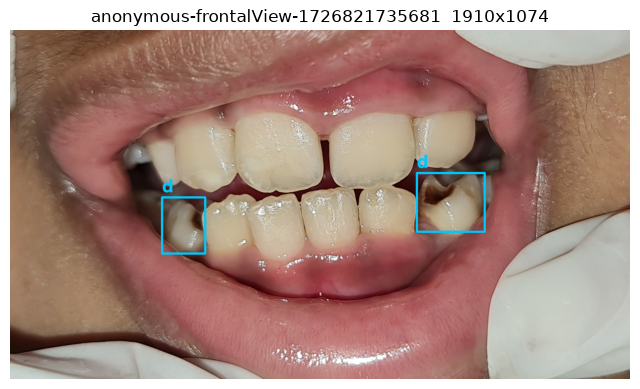

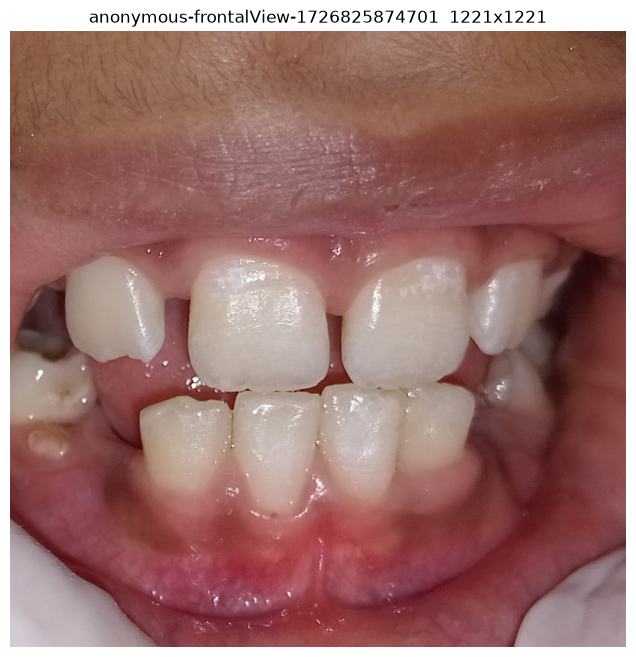

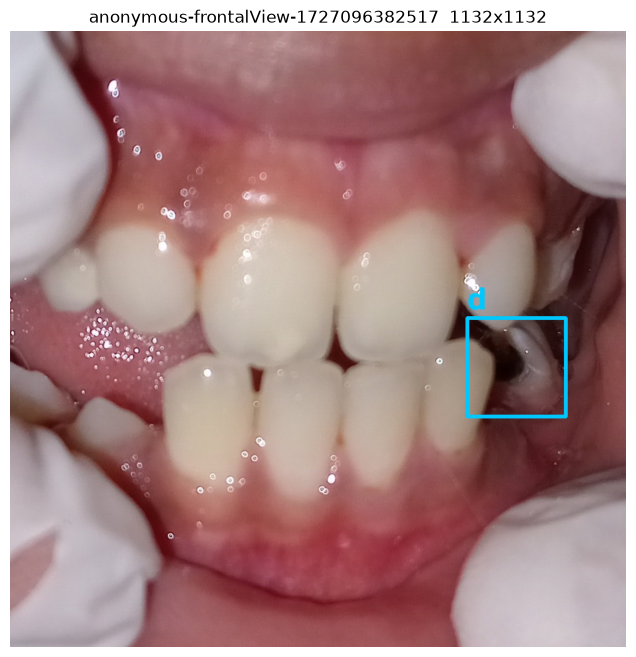

In [11]:
# draw the boxes.

import cv2
import matplotlib.pyplot as plt

NAMES  = {0: "D", 1: "d"}
COLORS = {0: (255, 60, 60), 1: (0, 200, 255)}

def yolo_to_xyxy(cx, cy, w, h, W, H):
    x1 = (cx - w / 2) * W        # left edge = center minus half the width, then scale to pixels
    y1 = (cy - h / 2) * H        # top    = center minus half the height
    x2 = (cx + w / 2) * W        # right  = center plus half the width
    y2 = (cy + h / 2) * H        # bottom = center plus half the height
    return int(x1), int(y1), int(x2), int(y2)

def show_labels(stem):
    img = cv2.cvtColor(cv2.imread(str(img_by_stem[stem])), cv2.COLOR_BGR2RGB)   # BGR trap from Practical 1
    H, W = img.shape[:2]
    for line in lbl_by_stem[stem].read_text().splitlines():
        if not line.strip():
            continue
        c, cx, cy, w, h = line.split()
        x1, y1, x2, y2 = yolo_to_xyxy(float(cx), float(cy), float(w), float(h), W, H)
        cv2.rectangle(img, (x1, y1), (x2, y2), COLORS[int(c)], 6)
        cv2.putText(img, NAMES[int(c)], (x1, max(y1 - 15, 40)), cv2.FONT_HERSHEY_SIMPLEX, 2, COLORS[int(c)], 4)
    plt.figure(figsize=(8, 8)); plt.imshow(img); plt.title(f"{stem[:45]}  {W}x{H}"); plt.axis("off"); plt.show()

good = [s for s in labeled if s not in bad_set]
for s in good[:3]:
    show_labels(s)

In [12]:
# how many people are there, and are they in both groups?

import re

def person_id(stem):
    m = re.match(r"anonymous_([\d-]+)_\d+_", stem)
    return m.group(1) if m else None

ids = Counter(person_id(s) for s in img_by_stem)
print("unique people:", sum(1 for k in ids if k), "| images without an ID:", ids[None])
print("images per person:", Counter(n for k, n in ids.items() if k))

groups = {}
for s, p in img_by_stem.items():
    if (pid := person_id(s)):
        groups.setdefault(pid, set()).add(p.relative_to(ROOT / "Images").parts[0])
print("people in BOTH retractors and no_retractors:", sum(len(g) > 1 for g in groups.values()))

unique people: 890 | images without an ID: 760
images per person: Counter({5: 852, 4: 11, 2: 10, 1: 8, 3: 8, 1149: 1})
people in BOTH retractors and no_retractors: 1


## Build the clean YOLO dataset

In [13]:
# confirm the timestamp works as a session ID

import re

def timestamp(stem):
    m = re.search(r"(\d{13})", stem)
    return m.group(1) if m else None

per_ts = Counter(timestamp(s) for s in img_by_stem)
print("most common ID:", ids.most_common(1))
print("images with no timestamp:", per_ts[None])
print("images per timestamp:", Counter(n for k, n in per_ts.items() if k))

most common ID: [('003', 1149)]
images with no timestamp: 0
images per timestamp: Counter({5: 1078, 1: 769, 4: 13, 2: 12, 3: 10})


In [14]:
# assign each image to a group, then split by group

import random

def capture_group(stem):
    return img_by_stem[stem].relative_to(ROOT / "Images").parts[0]

def group_key(stem):
    if capture_group(stem) == "pilot":
        return "pilot"                      # all pilot images go to train
    pid = person_id(stem)
    if pid and ids[pid] <= 5:               # a real person ID
        return "id_" + pid
    return "ts_" + timestamp(stem)          # placeholder ID, so use the session

keep = [s for s in labeled if s not in bad_set]
group_of = {s: group_key(s) for s in keep}

groups = sorted({g for g in group_of.values() if g != "pilot"})
random.Random(42).shuffle(groups)           # fixed seed, so the split is the same every run
n = len(groups)
val_groups  = set(groups[: int(0.15 * n)])
test_groups = set(groups[int(0.15 * n): int(0.30 * n)])

def split_of(stem):
    g = group_of[stem]
    if g in val_groups:  return "val"
    if g in test_groups: return "test"
    return "train"

print("images kept:", len(keep), "| groups:", n)

images kept: 2211 | groups: 1020


In [15]:
# write the YOLO folder structure, merging classes along the way

import shutil

OUT = Path("../data/yolo")
shutil.rmtree(OUT, ignore_errors=True)       # start clean on every run
for split in ["train", "val", "test"]:
    for sub in ["images", "labels"]:
        (OUT / split / sub).mkdir(parents=True, exist_ok=True)

for s in keep:
    sp, src = split_of(s), img_by_stem[s]
    shutil.copy2(src, OUT / sp / "images" / src.name)
    rows = [l.split() for l in lbl_by_stem[s].read_text().splitlines() if l.strip()]
    merged = ["0 " + " ".join(r[1:]) for r in rows]          # D and d become class 0, "caries"
    (OUT / sp / "labels" / f"{src.stem}.txt").write_text("\n".join(merged))

In [17]:
# check the result, including the leakage check

for sp in ["train", "val", "test"]:
    n_img = len(list((OUT / sp / "images").iterdir()))
    n_box = sum(len(f.read_text().splitlines()) for f in (OUT / sp / "labels").glob("*.txt"))
    print(f"{sp:5s} images={n_img:4d}  boxes={n_box:5d}")

g = {sp: {group_of[s] for s in keep if split_of(s) == sp} for sp in ["train", "val", "test"]}
print("people shared  train/val:", len(g["train"] & g["val"]),
      "| train/test:", len(g["train"] & g["test"]),
      "| val/test:", len(g["val"] & g["test"]))

train images=1632  boxes= 4887
val   images= 294  boxes=  896
test  images= 285  boxes=  903
people shared  train/val: 0 | train/test: 0 | val/test: 0


In [18]:
# write data.yaml, the file that tells YOLO where everything is

yaml_text = f"""path: {OUT.resolve().as_posix()}
train: train/images
val: val/images
test: test/images
names:
  0: caries
"""
(OUT / "data.yaml").write_text(yaml_text)
print(yaml_text)

path: D:/Wajahat/project/CV/dental-caries-yolo/data/yolo
train: train/images
val: val/images
test: test/images
names:
  0: caries



In [19]:
# a smoke test on CPU. This trains on 5% of the data for 1 epoch, just to prove the pipeline runs end to end before we move to Colab.

from ultralytics import YOLO

model = YOLO("yolo26n.pt")
model.train(data=str(OUT / "data.yaml"), epochs=1, imgsz=320, batch=8,
            fraction=0.05, device="cpu", workers=0,
            project="../runs", name="smoke")

New https://pypi.org/project/ultralytics/8.4.182 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.179  Python-3.11.17 torch-2.14.1+cpu CPU (Intel Core i7-6820HQ 2.70GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=..\data\yolo\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.05, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000020AE69C9950>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0480

## Train for real on Colab’s GPU

In [20]:
# Package the dataset

import shutil
from pathlib import Path

OUT = Path("../data/yolo")
for cache in OUT.rglob("*.cache"):
    cache.unlink()              # caches contain Windows paths; Colab will rebuild them
shutil.make_archive("../dental_yolo", "zip", OUT)
print("zip size (MB):", round(Path("../dental_yolo.zip").stat().st_size / 1e6))

zip size (MB): 515
